# Оценки, центральная предельная теорема и доверительные интервалы

**Темы:** генеральная совокупность и выборка, точечные оценки и их свойства, доля признака, центральная предельная теорема, стандартная ошибка, доверительные интервалы, метод моментов, метод максимального правдоподобия.

**Идея ноутбука:** создать генеральную совокупность, параметры которой известны заранее, брать из неё выборки и проверять, насколько хорошо по выборкам удаётся восстановить настоящие значения.

## Подготовка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

---
## 1. Генеральная совокупность и выборка

Генеральная совокупность — все объекты, которые нас интересуют. Обычно её параметры неизвестны, и их оценивают по выборке. Здесь генеральную совокупность мы создадим сами, поэтому сможем сравнить оценки с настоящими значениями.

### 1.1 Генеральные и выборочные характеристики

Создадим генеральную совокупность из 100 000 значений роста, распределённого нормально со средним 170 см и стандартным отклонением 8 см. Посчитаем её генеральное среднее и генеральную дисперсию.

Возьмём из неё случайную выборку объёмом $n = 30$ и посчитаем выборочное среднее, выборочную дисперсию $\sigma^2$ (деление на $n$) и исправленную выборочную дисперсию $S^2$ (деление на $n - 1$). Сравним их с генеральными значениями.

In [2]:
N = 100000
mu = 170
sigma = 8
population = np.random.normal(mu, sigma, N)
pop_mean = population.mean()
pop_var = np.sum((population-pop_mean)**2)/N
# либо сразу же формулой np.var(population) либо population.var()


n = 30
sample = np.random.choice(population, size=n, replace=False) # replace=False каждый человек может попасть в выборку только 1 раз
sample_mean = sample.mean()
sample_var = sample.var()
sample_var_corr = sample.var(ddof=1)


print(f"{'':<25}{'Генеральная':>14}{'Выборка':>12}")
print(f"{'Среднее':<25}{pop_mean:>14.2f}{sample_mean:>12.2f}")
print(f"{'Дисперсия':<25}{pop_var:>14.2f}{sample_var:>12.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>14}{sample_var_corr:>12.2f}")


                            Генеральная     Выборка
Среднее                          170.01      171.72
Дисперсия                         64.12       66.12
Исправленная дисперсия            -----       68.40


### 1.2 Несмещённость

Возьмём из генеральной совокупности 10 000 выборок объёмом $n = 5$. Для каждой выборки посчитаем выборочное среднее, выборочную дисперсию $\sigma^2$ и исправленную дисперсию $S^2$.

Усредним каждую из трёх оценок по всем 10 000 выборкам и сравним с генеральным средним и генеральной дисперсией. Определим, какие оценки несмещённые, а какая систематически ошибается и в какую сторону.

In [3]:
n_small = 5
n_samples = 10000
means = []
vars = []
vars_corr = []
for i in range(n_samples):
    sample_small = np.random.choice(population, size=n_small, replace=True) # Так как при значении False NumPy каждый раз перемешивает все 100 000 значений и только потом берёт первые 5
    # это очень долго и для 5 из 100 000 разницы между повторной и бесповторной выборкой практически нет, следовательно ставим True.
    means.append(sample_small.mean())
    vars.append(sample_small.var())
    vars_corr.append(sample_small.var(ddof=1))
    
avg_mean = np.mean(means)
avg_var = np.mean(vars)
avg_var_corr = np.mean(vars_corr)

print(f"{'':<25}{'Генеральная':>15}{'Выборка (30)':>20}{'Выборка (10000 по 5)':>25}")
print(f"{'Среднее':<25}{pop_mean:>15.2f}{sample_mean:>20.2f}{avg_mean:>25.2f}")
print(f"{'Дисперсия':<25}{pop_var:>15.2f}{sample_var:>20.2f}{avg_var:>25.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>15}{sample_var_corr:>20.2f}{avg_var_corr:>25.2f}")


                             Генеральная        Выборка (30)     Выборка (10000 по 5)
Среднее                           170.01              171.72                   169.98
Дисперсия                          64.12               66.12                    50.83
Исправленная дисперсия             -----               68.40                    63.53


In [4]:
# Тот же код но через таблицу в Numpy
table = np.random.choice(population, size=(n_samples,n_small), replace=True)
# далее можно рассчитать среднее и дисперсии для каждой строки
table_means = []
table_vars = []
table_vars_corr = []
table_means.append(table.mean(axis=1))
table_vars.append(table.var(axis=1))
table_vars_corr.append(table.var(axis=1, ddof=1))
avg_table_mean = np.mean(table_means)
avg_table_var = np.mean(table_vars)
avg_table_var_corr = np.mean(table_vars_corr)


print(f"{'':<25}{'Генеральная':>15}{'Выборка (30)':>20}{'Выборка (10000 по 5)':>25}")
print(f"{'Среднее':<25}{pop_mean:>15.2f}{sample_mean:>20.2f}{avg_table_mean:>25.2f}")
print(f"{'Дисперсия':<25}{pop_var:>15.2f}{sample_var:>20.2f}{avg_table_var:>25.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>15}{sample_var_corr:>20.2f}{avg_table_var_corr:>25.2f}")

                             Генеральная        Выборка (30)     Выборка (10000 по 5)
Среднее                           170.01              171.72                   170.03
Дисперсия                          64.12               66.12                    50.53
Исправленная дисперсия             -----               68.40                    63.16


Повторим тот же эксперимент для $n = 2, 5, 10, 30, 100$ и для каждого $n$ найдём, во сколько раз среднее значение $\sigma^2$ меньше генеральной дисперсии. Сравним это отношение с $\frac{n-1}{n}$.

In [5]:
n_values = [2, 5, 10, 30, 100]

print(f"{'n':>5}{'|':^5}{'avg_var':>10}{'pop_var':>15}{'ratio, %':>15}{'ratio_corr, %':>15}{'theory, %':>15}")
print("-"*7+"|"+"-"*73)
for n in n_values:
    table = np.random.choice(population, size=(n_samples,n), replace=True)
    avg_var = (table.var(axis=1)).mean()
    ratio = 100 - (avg_var/pop_var)*100
    avg_var_corr = (table.var(axis=1, ddof=1)).mean()
    ratio_corr = 100 - (avg_var_corr/pop_var)*100
    print(f"{n:>5}{'|':^5}{avg_var:>10.3f}{pop_var:>15.3f}{ratio:>15.3f}{ratio_corr:>15.3f}{100/n:>15.3f}")
    


    n  |     avg_var        pop_var       ratio, %  ratio_corr, %      theory, %
-------|-------------------------------------------------------------------------
    2  |      32.341         64.115         49.558         -0.883         50.000
    5  |      51.080         64.115         20.331          0.414         20.000
   10  |      57.638         64.115         10.103          0.115         10.000
   30  |      62.108         64.115          3.132         -0.209          3.333
  100  |      63.473         64.115          1.001          0.001          1.000


### 1.3 Состоятельность

Для объёмов выборки $n = 10, 100, 1\,000, 10\,000$ возьмём по одной выборке и посчитаем выборочное среднее. Выведем, насколько каждое из них отличается от генерального среднего.

In [6]:
n_values = [10,100,1000,10000]
print(f"{'n':>5}{'|':^5}{'sample_mean':>15}{'pop_mean':>15}{'diff, см':>15}")
print("-"*7+"|"+"-"*48)
for n in n_values:
    cons_sample = np.random.choice(population, size=n, replace=True)
    cons_mean = cons_sample.mean()
    diff = abs(pop_mean-cons_mean)
    print(f"{n:>5}{'|':^5}{cons_mean:>15.3f}{pop_mean:>15.3f}{diff:>15.3f}")

    n  |      sample_mean       pop_mean       diff, см
-------|------------------------------------------------
   10  |          172.173        170.008          2.165
  100  |          168.848        170.008          1.160
 1000  |          169.851        170.008          0.157
10000  |          170.035        170.008          0.027


Построим график: по оси x — объём выборки $n$ от 1 до 5 000, по оси y — выборочное среднее первых $n$ значений одной большой выборки. Горизонтальной линией отметим генеральное среднее.

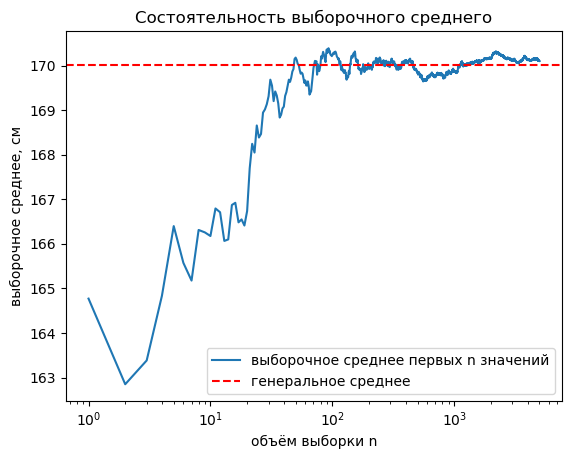

In [7]:
cons_n_max = 5000
cons_means = []
cons_big = np.random.choice(population, size=cons_n_max, replace=True)
for n in range(1, cons_n_max + 1):
    cons_means.append(cons_big[:n].mean())
   
plt.plot(np.arange(1, cons_n_max + 1), cons_means, label="выборочное среднее первых n значений")
plt.axhline(pop_mean, color="red", linestyle="--", label="генеральное среднее")
plt.xlabel("объём выборки n")
plt.ylabel("выборочное среднее, см")
plt.title("Состоятельность выборочного среднего")
plt.legend()
plt.xscale("log")
plt.show()
    
    

**Выводы к разделу 1:**

Если взять из генеральной совокупности одну небольшую выборку, её среднее и дисперсия получаются близкими к настоящим, но каждый раз немного другими — это дело случая.

Чтобы понять, ошибаются ли оценки в какую-то одну сторону, мы взяли 10 000 выборок и посмотрели, что выходит в среднем. Выборочное среднее и исправленная дисперсия попали точно в настоящие значения. А обычная дисперсия (где делим на n) оказалась заниженной. Поэтому по выборке дисперсию считают с делением на n − 1.

На графике видно, что чем больше выборка, тем ближе её среднее к настоящему: сначала оно сильно скачет, а потом успокаивается. Чем больше данных, тем точнее оценка.

---
## 2. Доля признака

Признак типа «да / нет» можно закодировать числами: «да» = 1, «нет» = 0. Тогда среднее таких значений равно доле «да», а дисперсия равна $w(1 - w)$.

### 2.1 Выборочная доля и её дисперсия

Создадим генеральную совокупность из 100 000 клиентов, где каждый с вероятностью $p = 0.27$ согласен купить услугу (1), а иначе не согласен (0). Посчитаем генеральную долю.

Возьмём выборку из 500 клиентов. Найдём выборочную долю $w$ двумя способами: как $\frac{m}{n}$ и как среднее нулей и единиц. Посчитаем дисперсию выборки по обычной формуле (деление на $n$) и сравним её с $w(1 - w)$.

In [8]:
prop_N = 100000
prop_n = 500
prop_p_true = 0.27

prop_population = np.random.binomial(1, prop_p_true, size=prop_N)
prop_p = prop_population.mean()# тут мы посчитали генеральную долю, то, что на самом деле есть в нашей совокупности
# генеральная доля - это как бы псевдо мат ожидание
prop_sample = np.random.choice(prop_population, size=prop_n, replace=True)
prop_m = prop_sample.sum() # количество тех, кто обладает признаком
prop_w_count = prop_m/prop_n # подсчет выборочной доли по формуле w = m/n
prop_w_mean = prop_sample.mean() # подсчет выборочной доли через среднее 0 и 1

prop_var_count = prop_w_count*(1-prop_w_count) # подсчет дисперсии по формуле w(1−w)
prop_var_var = prop_sample.var() # подсчет через обычную дисперсию

print(f"Генеральная доля p:                 {prop_p:.4f}")
print(f"В выборке «да»: {prop_m} из {prop_n}")
print()
print(f"{'':<30}{'способ 1':>12}{'способ 2':>12}")
print(f"{'Выборочная доля w':<30}{prop_w_count:>12.4f}{prop_w_mean:>12.4f}")
print(f"{'Дисперсия доли':<30}{prop_var_count:>12.4f}{prop_var_var:>12.4f}")



Генеральная доля p:                 0.2715
В выборке «да»: 120 из 500

                                  способ 1    способ 2
Выборочная доля w                   0.2400      0.2400
Дисперсия доли                      0.1824      0.1824


Построим график функции $w(1 - w)$ для $w$ от 0 до 1. Отметим, при каком $w$ дисперсия доли максимальна и чему она равна.

Максимум дисперсии доли: w = 0.50, w(1 − w) = 0.25


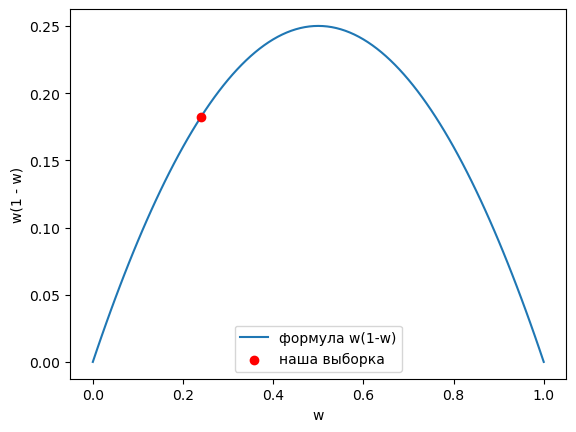

In [9]:
prop_w_grid = np.linspace(0,1,101)
prop_var_grid = prop_w_grid*(1 - prop_w_grid)
print(f"Максимум дисперсии доли: w = {prop_w_grid[np.argmax(prop_var_grid)]:.2f}, w(1 − w) = {prop_var_grid.max():.2f}")
plt.plot(prop_w_grid, prop_var_grid, label="формула w(1-w)" )
plt.xlabel('w')
plt.ylabel('w(1 - w)')
plt.scatter(prop_w_count, prop_var_count, color='red', zorder=5, label="наша выборка")
plt.legend()
plt.show()




**Выводы к разделу 2:**


Создали генеральную совокупность из 100 000 клиентов, где «да» = 1, «нет» = 0, и посчитали генеральную долю. Потом опросили 500 клиентов и нашли выборочную долю. Она получилась немного меньше генеральной — это обычный случайный промах выборки, с другими 500 клиентами она могла бы выйти и больше.

Долю посчитали двумя способами: как m / n и как среднее нулей и единиц — результат совпал. Дисперсию тоже двумя способами: обычной формулой и как w(1 − w) — тоже совпало. То есть для признака «да/нет» среднее — это доля, а дисперсия — произведение доли «да» на долю «нет».

На графике w(1 − w) видно, что дисперсия максимальна при w = 0.5 и равна 0.25: разброс самый большой, когда «да» и «нет» поровну. А при w = 0 или w = 1, когда все ответили одинаково, разброса нет вообще.

---
## 3. Центральная предельная теорема (CLT)

Если брать много выборок объёма $n$ и у каждой считать среднее, то при достаточно большом $n$ эти средние распределены нормально — независимо от того, какое распределение было у исходных данных. Центр этого распределения совпадает с генеральным средним $\mu$, а его стандартное отклонение равно стандартной ошибке $se = \frac{\sigma}{\sqrt{n}}$.

### 3.1 Исходные распределения

Возьмём два распределения, совсем не похожих на нормальное:
- равномерное на отрезке $[0, 10]$;
- показательное с $\lambda = 0.5$.

Сгенерируем по 100 000 значений из каждого и построим их гистограммы рядом. Посчитаем по формулам их матожидания и стандартные отклонения.

                  μ (теория)  mean (симуляция)  σ (теория)  std (симуляция)
Равномерное            5.000             5.002       2.887            2.895
Показательное          2.000             2.003       2.000            2.011


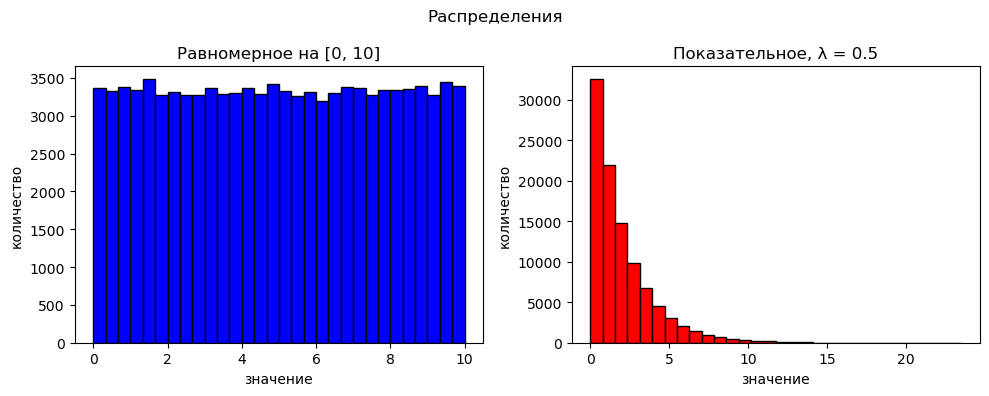

In [10]:
clt_N = 100000

# равномерное распределение
clt_a = 0
clt_b = 10
clt_unif = np.random.uniform(clt_a, clt_b, clt_N)
clt_unif_mu = (clt_a + clt_b) / 2
clt_unif_var = (clt_b - clt_a)**2/12
clt_unif_sigma = np.sqrt(clt_unif_var)

# показательное распределение
clt_lam = 0.5
clt_expo = np.random.exponential(1/clt_lam, clt_N)
clt_expo_mu = 1/clt_lam
clt_expo_var = 1/(clt_lam**2)
clt_expo_sigma = np.sqrt(clt_expo_var)

print(f"{'':<16}{'μ (теория)':>12}{'mean (симуляция)':>18}{'σ (теория)':>12}{'std (симуляция)':>17}")
print(f"{'Равномерное':<16}{clt_unif_mu:>12.3f}{clt_unif.mean():>18.3f}{clt_unif_sigma:>12.3f}{clt_unif.std():>17.3f}")
print(f"{'Показательное':<16}{clt_expo_mu:>12.3f}{clt_expo.mean():>18.3f}{clt_expo_sigma:>12.3f}{clt_expo.std():>17.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].hist(clt_unif, bins=30, color='blue', edgecolor='black')
axes[0].set_title('Равномерное на [0, 10]')
axes[0].set_xlabel('значение')
axes[0].set_ylabel('количество')

axes[1].hist(clt_expo, bins=30, color='red', edgecolor='black')
axes[1].set_title('Показательное, λ = 0.5')
axes[1].set_xlabel('значение')
axes[1].set_ylabel('количество')

fig.suptitle('Распределения')
plt.tight_layout()
plt.show()




### 3.2 Распределение выборочных средних

Для каждого из двух распределений и для объёмов выборки $n = 1, 2, 5, 30$ сгенерируем 10 000 выборок и посчитаем их средние. Построим гистограммы этих средних на одной сетке графиков: строки — распределения, столбцы — объёмы выборки.

Опишем, как меняется форма гистограммы с ростом $n$.

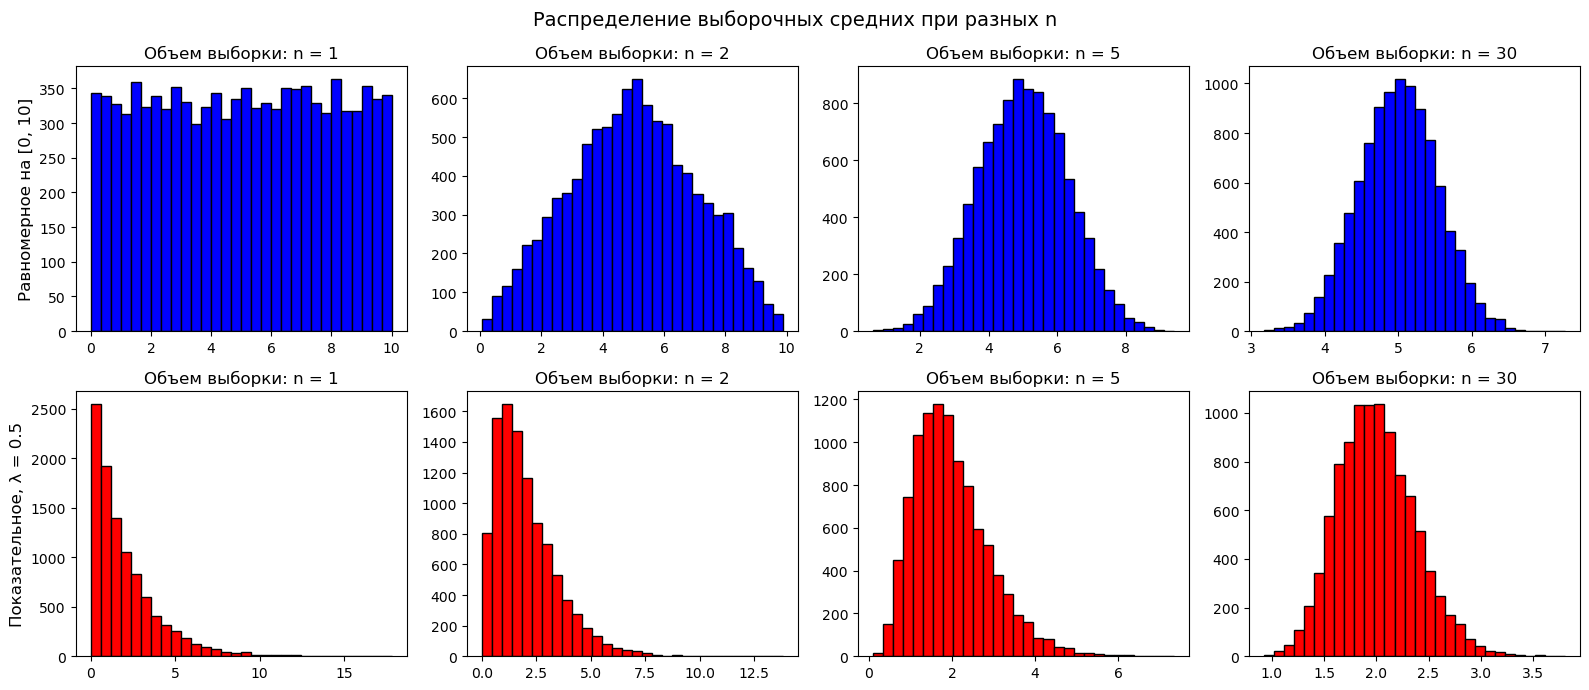

In [11]:
clt_n_values = [1,2,5,30]
clt_n_samples = 10000

fig, axes = plt.subplots(2,4, figsize=(16, 7))
for i, n in enumerate(clt_n_values):
    clt_unif_table = np.random.choice(clt_unif, (clt_n_samples, n), replace=True)
    clt_unif_means = clt_unif_table.mean(axis=1) # массив из 10000 средних
    
    clt_expo_table = np.random.choice(clt_expo, (clt_n_samples, n), replace=True)
    clt_expo_means = clt_expo_table.mean(axis=1) # массив из 10000 средних
    
    axes[0,i].hist(clt_unif_means, bins=30, color='blue', edgecolor='black')
    axes[0,i].set_title(f"Объем выборки: n = {n}")
    axes[1,i].hist(clt_expo_means, bins=30, color='red', edgecolor='black')
    axes[1,i].set_title(f"Объем выборки: n = {n}")
    
    
axes[0, 0].set_ylabel("Равномерное на [0, 10]", fontsize=12)
axes[1, 0].set_ylabel("Показательное, λ = 0.5", fontsize=12)
fig.suptitle("Распределение выборочных средних при разных n", fontsize=14)
plt.tight_layout()
plt.show()

На гистограмму средних при $n = 30$ для показательного распределения наложим кривую плотности нормального распределения с центром $\mu$ и стандартным отклонением $\frac{\sigma}{\sqrt{n}}$.

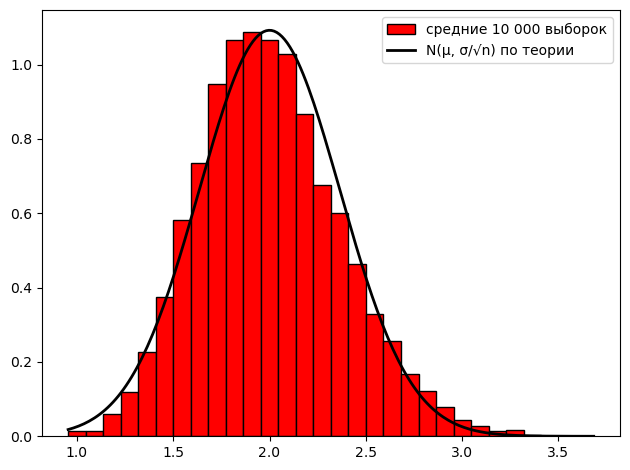

In [12]:
clt_expo_table_30 = np.random.choice(clt_expo, (clt_n_samples, 30), replace=True)
clt_expo_means_30 = clt_expo_table_30.mean(axis=1)
clt_se_30 = clt_expo_sigma/np.sqrt(30) # стандартная ошибка
clt_x = np.linspace(clt_expo_means_30.min(), clt_expo_means_30.max(),200)

plt.hist(clt_expo_means_30, bins=30, color='red', edgecolor='black', density=True, label='средние 10 000 выборок')
clt_y = stats.norm.pdf(clt_x, clt_expo_mu, clt_se_30)
plt.plot(clt_x, clt_y, color="black", linewidth=2, label='N(μ, σ/√n) по теории')
plt.legend()
plt.tight_layout()
plt.show()

### 3.3 Стандартная ошибка

Для показательного распределения и объёмов $n = 4, 16, 64, 256$ сгенерируем по 10 000 выборок, посчитаем стандартное отклонение их средних и сравним его с теоретической стандартной ошибкой $\frac{\sigma}{\sqrt{n}}$. Выведем результат таблицей.

Посмотрим, во сколько раз уменьшается стандартная ошибка при увеличении $n$ в 4 раза.

In [13]:
clt_n_samples = 10000
clt_se_n_values = [4,16,64,256]
print(f"{'n':>5}{'по симуляции':>15}{'по теории':>12}")
for n in clt_se_n_values:
    clt_se_table = np.random.choice(clt_expo, (clt_n_samples, n), replace=True)
    clt_se_means = clt_se_table.mean(axis=1)
    clt_se_sim = clt_se_means.std() # разброс средних по симуляции
    clt_se_theory = clt_expo_sigma/np.sqrt(n) # разброс средних по теории
    print(f"{n:>5}{clt_se_sim:>15.3f}{clt_se_theory:>12.3f}")
    

    n   по симуляции   по теории
    4          1.000       1.000
   16          0.501       0.500
   64          0.251       0.250
  256          0.125       0.125


### 3.4 Правило трёх сигм для средних

Для выборочных средних из показательного распределения при $n = 30$ посчитаем, какая доля средних попадает в интервалы $\mu \pm se$, $\mu \pm 2\,se$, $\mu \pm 3\,se$. Сравним с теоретическими 68.27%, 95.45%, 99.73%.

Для сравнения посчитаем, какая доля **отдельных значений** показательного распределения попадает в $\mu \pm \sigma$, $\mu \pm 2\sigma$, $\mu \pm 3\sigma$.

In [14]:
# возьмем данные из 3.2 (для n=30)
print(f"{'':>6}{'средние':>12}{'отдельные значения':>22}{'теория':>10}")
for k in range(1,4):
    # средние: границы для se
    clt_lower = clt_expo_mu - k*clt_se_30 
    clt_upper = clt_expo_mu + k*clt_se_30
    clt_share_means = ((clt_expo_means_30>clt_lower)&(clt_expo_means_30<clt_upper)).mean()
    
    # отдельные значения: границы через σ
    clt_lower_v = clt_expo_mu - k*clt_expo_sigma
    clt_upper_v = clt_expo_mu + k*clt_expo_sigma
    clt_share_values = ((clt_expo>clt_lower_v)&(clt_expo<clt_upper_v)).mean()
    
    # теория для номрального распределения
    clt_share_theory = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"{'±' + str(k):>6}{clt_share_means:>12.1%}{clt_share_values:>22.1%}{clt_share_theory:>10.1%}")
    
    
    

           средние    отдельные значения    теория
    ±1       68.0%                 86.5%     68.3%
    ±2       95.5%                 94.9%     95.4%
    ±3       99.5%                 98.1%     99.7%


**Выводы к разделу 3:**

Центральная предельная теорема: если брать много выборок одного объёма из любого распределения и у каждой считать среднее, то эти средние распределяются нормально.

Мы взяли два распределения, совсем не похожих на колокол: равномерное и показательное. Для каждого взяли по 10 000 выборок объёмом 1, 2, 5 и 30 и построили гистограммы их средних. Чем больше объём выборки, тем сильнее гистограмма средних похожа на колокол. При n = 30 на гистограмму средних наложили кривую нормального распределения с центром μ и шириной σ/√n — она почти совпала с гистограммой.

Потом сравнили разброс средних по симуляции с формулой σ/√n — они совпали при всех объёмах выборки. Значит, ширину колокола средних можно посчитать по формуле, не беря тысячи выборок. Ещё видно, что при увеличении выборки в 4 раза ошибка уменьшается только в 2 раза: из-за корня в формуле.

Правило трёх сигм сработало для средних (68%, 95%, 99.7%), но не сработало для самих значений показательного распределения. То есть правила нормального распределения можно применять к средним, даже когда сами данные не нормальные.

На практике это значит, что по одной выборке можно оценить, насколько её среднее может отличаться от настоящего. На этом строятся доверительные интервалы.

---
## 4. Доверительные интервалы

Доверительный интервал $(\tilde{x} - \Delta; \ \tilde{x} + \Delta)$ с доверительной вероятностью $\gamma$ накрывает неизвестный параметр генеральной совокупности. Точность $\Delta = t \cdot se$, где $t$ берётся:
- из функции Лапласа $\Phi(t) = \frac{\gamma}{2}$, если генеральная $\sigma$ известна или выборка большая;
- из распределения Стьюдента с $k = n - 1$ степенями свободы, если $\sigma$ неизвестна и выборка малая.

### 4.1 Генеральная σ известна

Возьмём из генеральной совокупности роста (раздел 1) выборку объёмом $n = 25$. Считая, что генеральное стандартное отклонение $\sigma = 8$ известно, построим доверительный интервал для генерального среднего с $\gamma = 0.95$. Проверим, накрывает ли он настоящее среднее.

In [15]:
ci_n = 25
ci_gamma = 0.95 # доверительная вероятность
ci_sigma = 8 # как и в генеральной совокупности

ci_sample = np.random.choice(population, size=ci_n, replace=True)
ci_mean = ci_sample.mean()
ci_tail = (1-ci_gamma)/2 # на каждый хвост: (1-0.95)/2 = 0.025
ci_left_area = 1 - ci_tail # область слева от правой границы: 1 - 0.025 = 0.975
ci_t = stats.norm.ppf(ci_left_area) # Percent point function - функция процентной точки - точка слева от которой 97.5% 
ci_delta = ci_t * np.sqrt((ci_sigma**2)/ci_n)
ci_lower_value = ci_mean - ci_delta
ci_upper_value = ci_mean + ci_delta
print(f"Доверительный интервал при выборке n = {ci_n}, с доверительной вероятностью {ci_gamma:.2f}: ({ci_lower_value:.2f}, {ci_upper_value:.2f})")
if (ci_lower_value<pop_mean)&(ci_upper_value>pop_mean):
    print(f"Генеральное среднее {pop_mean:.2f} попадает в интервал")
else:
    print(f"Генеральное среднее {pop_mean:.2f} не попадает в интервал")


Доверительный интервал при выборке n = 25, с доверительной вероятностью 0.95: (165.63, 171.91)
Генеральное среднее 170.01 попадает в интервал


### 4.2 Генеральная σ неизвестна, малая выборка

Возьмём выборку объёмом $n = 10$. Построим доверительный интервал с $\gamma = 0.95$ по исправленной выборочной дисперсии и распределению Стьюдента.

Для той же выборки построим интервал, взяв $t$ из функции Лапласа, и сравним ширину двух интервалов. Выведем значения $t$ Стьюдента для $k = 4, 9, 29, 99, 999$ при $\gamma = 0.95$ рядом с $t$ из функции Лапласа.

In [16]:
ci_small_n = 10
ci_small_k = ci_small_n - 1 # число степеней свободы, необходимо для распределения Стьюдента
ci_small_gamma = 0.95

ci_small_sample = np.random.choice(population, size=ci_small_n, replace=True)
ci_small_mean = ci_small_sample.mean()
ci_small_var = ci_small_sample.var(ddof=1)
ci_small_tail = (1-ci_small_gamma)/2
ci_small_area = 1 - ci_small_tail
ci_small_t = stats.t.ppf(ci_small_area, ci_small_k) # такая формула для Стьюдента
ci_small_delta = ci_small_t*np.sqrt((ci_small_var)/ci_small_n)
ci_small_lower_value = ci_small_mean - ci_small_delta
ci_small_upper_value = ci_small_mean + ci_small_delta
print(f"Доверительный интервал (Стьюдент) при выборке n = {ci_small_n}, с доверительной вероятностью {ci_small_gamma:.2f}: ({ci_small_lower_value:.2f}, {ci_small_upper_value:.2f})")
if (ci_small_lower_value<pop_mean)&(ci_small_upper_value>pop_mean):
    print(f"Генеральное среднее {pop_mean:.2f} попадает в интервал")
else:
    print(f"Генеральное среднее {pop_mean:.2f} не попадает в интервал")
    
ci_small_t_lapl = stats.norm.ppf(ci_small_area) # Теперь посчитаем, взяв t из функции Лапласса
ci_small_delta_lapl = ci_small_t_lapl*np.sqrt((ci_small_var)/ci_small_n)
ci_small_lower_value_lapl = ci_small_mean - ci_small_delta_lapl
ci_small_upper_value_lapl = ci_small_mean + ci_small_delta_lapl
print(f"Доверительный интервал (Лаплас) при выборке n = {ci_small_n}, с доверительной вероятностью {ci_small_gamma:.2f}: ({ci_small_lower_value_lapl:.2f}, {ci_small_upper_value_lapl:.2f})")
if (ci_small_lower_value_lapl<pop_mean)&(ci_small_upper_value_lapl>pop_mean):
    print(f"Генеральное среднее {pop_mean:.2f} попадает в интервал")
else:
    print(f"Генеральное среднее {pop_mean:.2f} не попадает в интервал")
    
print()
ci_small_width = 2 * ci_small_delta
ci_small_width_lapl = 2 * ci_small_delta_lapl
print(f"t Стьюдента = {ci_small_t:.3f}, t Лапласа = {ci_small_t_lapl:.3f}")
print(f"Ширина: Стьюдент {ci_small_width:.2f}, Лаплас {ci_small_width_lapl:.2f}, "
      f"Стьюдент шире в {ci_small_width / ci_small_width_lapl:.2f} раза")


print()
ci_k_values = [4,9,29,99,999]
print(f"{'k':>6}{'n = k + 1':>12}{'t Стьюдента':>15}{'t Лапласа':>12}")
for k in ci_k_values:
    ci_k_t_student = stats.t.ppf(ci_small_area, k)
    print(f"{k:>6}{k + 1:>12}{ci_k_t_student:>15.3f}{ci_small_t_lapl:>12.3f}")
    

Доверительный интервал (Стьюдент) при выборке n = 10, с доверительной вероятностью 0.95: (165.02, 178.60)
Генеральное среднее 170.01 попадает в интервал
Доверительный интервал (Лаплас) при выборке n = 10, с доверительной вероятностью 0.95: (165.93, 177.69)
Генеральное среднее 170.01 попадает в интервал

t Стьюдента = 2.262, t Лапласа = 1.960
Ширина: Стьюдент 13.57, Лаплас 11.76, Стьюдент шире в 1.15 раза

     k   n = k + 1    t Стьюдента   t Лапласа
     4           5          2.776       1.960
     9          10          2.262       1.960
    29          30          2.045       1.960
    99         100          1.984       1.960
   999        1000          1.962       1.960


### 4.3 Что значит «95%»

Возьмём 100 выборок объёмом $n = 20$ и для каждой построим доверительный интервал с $\gamma = 0.95$ (σ неизвестна). Посчитаем, сколько из 100 интервалов накрыли генеральное среднее.

Нарисуем все 100 интервалов горизонтальными отрезками друг под другом: интервалы, накрывшие генеральное среднее, одним цветом, не накрывшие — другим. Вертикальной линией отметим генеральное среднее.

Во сколько интервалов попало генеральное среднее: 94


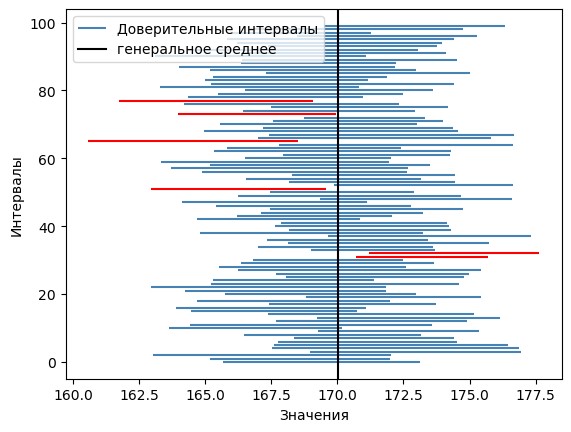

In [17]:
ci_cov_n = 20 # cov - coverage 
ci_cov_k = ci_cov_n - 1
ci_cov_m = 100
ci_cov_gamma = 0.95 

ci_cov_table = np.random.choice(population, size=(ci_cov_m, ci_cov_n), replace=True)
ci_cov_means = ci_cov_table.mean(axis=1)
ci_cov_S = np.sqrt(ci_cov_table.var(axis=1, ddof=1))

# n<30 -> Стьюдент
ci_cov_tail = (1 - ci_cov_gamma)/2
ci_cov_area = 1 - ci_cov_tail 
ci_cov_t = stats.t.ppf(ci_cov_area, ci_cov_k)
ci_cov_delta = ci_cov_t * ci_cov_S/np.sqrt(ci_cov_n)
ci_cov_lower = ci_cov_means - ci_cov_delta 
ci_cov_upper = ci_cov_means + ci_cov_delta
ci_cov_covers = (ci_cov_lower < pop_mean) & (pop_mean < ci_cov_upper) # 100 значений True/False (накрыл или нет)
ci_cov_covers_count = ci_cov_covers.sum()
print(f"Во сколько интервалов попало генеральное среднее: {ci_cov_covers_count}")

ci_cov_colors = np.where(ci_cov_covers, "steelblue", "red")
plt.hlines(np.arange(ci_cov_m),ci_cov_lower, ci_cov_upper, colors=ci_cov_colors, label="Доверительные интервалы")
plt.axvline(pop_mean, color='black', label="генеральное среднее")
plt.ylabel("Интервалы")
plt.xlabel("Значения")
plt.legend()
plt.show()


Повторим эксперимент для 10 000 выборок и доверительных вероятностей $\gamma = 0.90, 0.95, 0.99$. Сравним долю накрывших интервалов с $\gamma$.

In [18]:
ci_cov_n = 20
ci_cov_k = ci_cov_n - 1
ci_cov_m = 10000
ci_cov_gammas = [0.9,0.95,0.99]

ci_cov_table = np.random.choice(population, size=(ci_cov_m, ci_cov_n), replace=True)
ci_cov_means = ci_cov_table.mean(axis=1)
ci_cov_S = np.sqrt(ci_cov_table.var(axis=1, ddof=1))

print(f"{'γ':>6}{'накрыли':>12}{'накрыли, %':>12}")
for gamma in ci_cov_gammas:
    ci_cov_tail = (1 - gamma)/2
    ci_cov_area = 1 - ci_cov_tail 
    ci_cov_t = stats.t.ppf(ci_cov_area, ci_cov_k)
    ci_cov_delta = ci_cov_t * ci_cov_S/np.sqrt(ci_cov_n)
    ci_cov_lower = ci_cov_means - ci_cov_delta 
    ci_cov_upper = ci_cov_means + ci_cov_delta
    ci_cov_covers = (ci_cov_lower < pop_mean) & (pop_mean < ci_cov_upper)
    ci_cov_covers_count = ci_cov_covers.sum()
    print(f"{gamma:>6.2f}{ci_cov_covers_count:>12}{ci_cov_covers.mean():>12.1%}")

     γ     накрыли  накрыли, %
  0.90        8978       89.8%
  0.95        9486       94.9%
  0.99        9887       98.9%


### 4.4 От чего зависит ширина интервала

Посчитаем точность $\Delta$ для генеральной совокупности роста при известной $\sigma = 8$ для всех сочетаний $n = 10, 40, 160$ и $\gamma = 0.90, 0.95, 0.99$. Выведем результат таблицей: строки — $n$, столбцы — $\gamma$.

In [19]:
ci_w_ns = [10,40,160] # w - width - ширина
ci_w_gammas = [0.9,0.95,0.99]
ci_w_sigma = 8

print(f"{'n':>5}", end="") # end="" не переносит на следующую строку
for gamma in ci_w_gammas:
    print(f"{'γ = ' + str(gamma):>12}", end="")
print()

for n in ci_w_ns:
    print(f"{n:>5}", end="") # в начале строки — n
    for gamma in ci_w_gammas:
        ci_w_tail = (1 - gamma)/2
        ci_w_area = 1 - ci_w_tail 
        ci_w_t = stats.norm.ppf(ci_w_area)
        ci_w_delta = ci_w_t * ci_w_sigma/np.sqrt(n)
        print(f"{ci_w_delta:>12.2f}", end="")
    print()
    

    n     γ = 0.9    γ = 0.95    γ = 0.99
   10        4.16        4.96        6.52
   40        2.08        2.48        3.26
  160        1.04        1.24        1.63


### 4.5 Доверительный интервал для доли

Для генеральной совокупности клиентов из раздела 2 возьмём выборку из 500 клиентов и построим доверительный интервал для генеральной доли с $\gamma = 0.95$:

$$\Delta = t \cdot \sqrt{\frac{w(1-w)}{n}}$$

Проверим, накрывает ли он генеральную долю. Повторим для 1 000 выборок и посчитаем, какая доля интервалов накрыла генеральную долю.

In [20]:
ci_prop_n = 500
ci_prop_gamma = 0.95 

ci_prop_sample = np.random.choice(prop_population, size=ci_prop_n, replace=True)
ci_prop_w_mean = ci_prop_sample.mean() # подсчет выборочной доли через среднее 0 и 1
ci_prop_tail = (1 - ci_prop_gamma)/2
ci_prop_area = 1 - ci_prop_tail
ci_prop_t = stats.norm.ppf(ci_prop_area)
ci_prop_delta = ci_prop_t*np.sqrt((ci_prop_w_mean*(1-ci_prop_w_mean))/ci_prop_n)
ci_prop_lower = ci_prop_w_mean - ci_prop_delta
ci_prop_upper = ci_prop_w_mean + ci_prop_delta
if (ci_prop_lower<prop_p)&(ci_prop_upper>prop_p):
    print(f"Генеральная доля {prop_p:.1%} попадает в интервал ({ci_prop_lower:.1%}; {ci_prop_upper:.1%})")
else:
    print(f"Генеральная доля {prop_p:.1%} не попадает в интервал ({ci_prop_lower:.1%}; {ci_prop_upper:.1%})")



Генеральная доля 27.1% попадает в интервал (22.7%; 30.5%)


In [21]:
ci_prop_m = 1000
ci_prop_table = np.random.choice(prop_population, size=(ci_prop_m, ci_prop_n), replace=True)
ci_prop_w_mean = ci_prop_table.mean(axis=1) # 1000 выборочных средних
ci_prop_t = stats.norm.ppf(ci_prop_area)
ci_prop_delta = ci_prop_t*np.sqrt((ci_prop_w_mean*(1-ci_prop_w_mean))/ci_prop_n)
ci_prop_lower = ci_prop_w_mean - ci_prop_delta # 1000 левых границ
ci_prop_upper = ci_prop_w_mean + ci_prop_delta # 1000 правых границ
ci_prop_covers = (ci_prop_lower<prop_p)&(ci_prop_upper>prop_p) # 1000 значений True/False
print(f"Накрыли генеральную долю {prop_p:.1%}: {ci_prop_covers.mean():.1%} интервалов из {ci_prop_m}")


Накрыли генеральную долю 27.1%: 94.9% интервалов из 1000


**Выводы к разделу 4:**

Доверительный интервал — это промежуток вокруг выборочного среднего, который с заданной вероятностью накрывает настоящее генеральное среднее. Его ширина: Δ = t · se, где t зависит от того, насколько уверенными мы хотим быть.

Если генеральная σ известна, t берём из функции Лапласа (для 95% это 1.96). Если σ неизвестна и выборка маленькая, вместо σ подставляем исправленное S, а t берём из распределения Стьюдента. При n = 10 интервал Стьюдента получился шире в 1.15 раза: это запас на то, что S посчитана всего по 10 значениям. С ростом выборки t Стьюдента приближается к 1.96, и при n > 30 разницы почти нет.

Чтобы проверить, что значит «95%», построили 100 интервалов по разным выборкам: примерно 95 из них накрыли генеральное среднее, а около 5 промахнулись. На 10 000 выборок доля накрывших совпала с γ: 90%, 95% и 99%.

Ширина интервала зависит от объёма выборки и уверенности: при увеличении n в 4 раза интервал сужается в 2 раза, а чем выше γ, тем интервал шире.

Для доли интервал строится так же, только вместо S² стоит w(1 − w). По 500 клиентам долю удалось оценить с точностью примерно ±4%, и 95% таких интервалов накрыли настоящую долю.

---
## 5. Метод моментов и метод максимального правдоподобия

Оба метода находят неизвестные параметры распределения известного вида по выборке:
- **метод моментов** приравнивает теоретические моменты к выборочным;
- **метод максимального правдоподобия** ищет параметры, при которых функция правдоподобия $L(\theta) = \prod f(x_i, \theta)$ максимальна. Вместо самой $L$ удобно максимизировать её логарифм $\ln L(\theta) = \sum \ln f(x_i, \theta)$: максимум достигается в той же точке.

### 5.1 Показательное распределение: метод моментов

Сгенерируем 200 значений времени ожидания из показательного распределения с $\lambda = 0.5$ и будем считать, что $\lambda$ нам неизвестна. Оценим $\lambda$ методом моментов и сравним с настоящим значением.

In [22]:
mm_n = 200
mm_lam_true = 0.5
mm_sample = np.random.exponential(1/mm_lam_true, mm_n)
mm_mean = mm_sample.mean()
# M(x) = mm_mean; M(x) = 1/mm_lam
mm_lam = 1/mm_mean 
print(f"Лямбда полученная методом моментов: {mm_lam:.3f}")
print(f"Настоящая лямбда {mm_lam_true:.2f}")

Лямбда полученная методом моментов: 0.467
Настоящая лямбда 0.50


### 5.2 Показательное распределение: метод максимального правдоподобия

Для тех же 200 значений посчитаем логарифм функции правдоподобия для $\lambda$ от 0.05 до 2 с шагом 0.001 и построим график $\ln L(\lambda)$. Найдём $\lambda$, при которой график достигает максимума, и сравним её с формулой $\lambda = \frac{n}{\sum x_i}$ и с оценкой метода моментов.

λ методом максимального правдоподобия: 0.467
λ по формуле n / Σxᵢ: 0.467


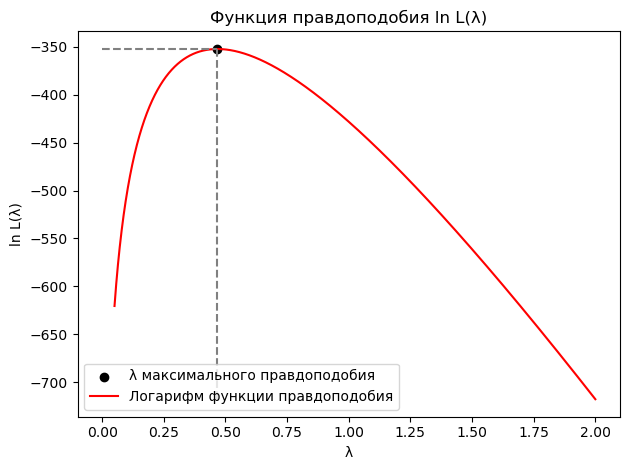

In [23]:
# дан шаг, используем np.arange, а не linspace
mle_lam_grid = np.arange(0.05, 2.001, 0.001)
mle_logL = []
for lam in mle_lam_grid:
    mle_dens = lam*np.exp(-1*lam*mm_sample) # плотность при 1 лямбда для всех 200 точек
    mle_dens_log = np.log(mle_dens)
    mle_dens_log_sum = mle_dens_log.sum()
    mle_logL.append(mle_dens_log_sum)
    
mle_maxidx = np.argmax(mle_logL)
mle_maxlam = mle_lam_grid[mle_maxidx]
mle_maxlam_formula = mm_n/mm_sample.sum()
print(f"λ методом максимального правдоподобия: {mle_maxlam:.3f}")
print(f"λ по формуле n / Σxᵢ: {mle_maxlam_formula:.3f}")

plt.scatter(mle_maxlam, np.max(mle_logL), color='black', label='λ максимального правдоподобия')
plt.plot(mle_lam_grid, mle_logL, color="red", label="Логарифм функции правдоподобия")
plt.vlines(mle_maxlam, np.max(mle_logL), np.min(mle_logL), linestyles="--", color="gray") 
plt.hlines(np.max(mle_logL),0, mle_maxlam, linestyles="--", color="gray")
plt.title("Функция правдоподобия ln L(λ)")
plt.xlabel("λ")   
plt.ylabel("ln L(λ)")
plt.legend()
plt.tight_layout()
plt.show()
    
    


Для первых трёх значений выборки построим график плотности показательного распределения при найденной $\lambda$, отметим три значения на оси x и высоту кривой над каждым из них. Посчитаем произведение этих высот и сравним его с произведением высот при $\lambda = 0.2$ и $\lambda = 2$.

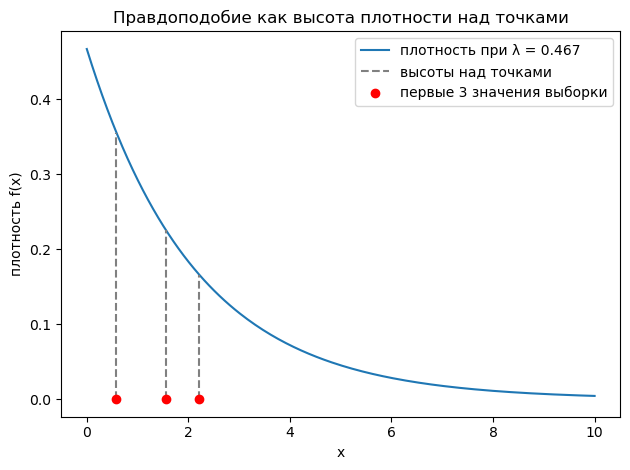

       λ   L (произведение высот)
   0.200                  0.00335
   0.467                  0.01332
   2.000                  0.00132


In [24]:
mle_x3 = mm_sample[:3]
mle_x_grid = np.linspace(0, 10, num=200)
mle_y_grid = mle_maxlam*np.exp(-1*mle_maxlam*mle_x_grid)
mle_h3 = mle_maxlam*np.exp(-1*mle_maxlam*mle_x3)
plt.plot(mle_x_grid, mle_y_grid, label=f"плотность при λ = {mle_maxlam:.3f}")
plt.vlines(mle_x3, 0, mle_h3, color="gray", linestyles="--", label="высоты над точками")
plt.scatter(mle_x3, np.zeros(3), color="red", zorder=5, label="первые 3 значения выборки")
plt.title("Правдоподобие как высота плотности над точками")
plt.xlabel("x")
plt.ylabel("плотность f(x)")
plt.legend()
plt.tight_layout()
plt.show()

# произведение высот (правдоподобие трёх точек) при разных λ
print(f"{'λ':>8}{'L (произведение высот)':>25}")
for lam in [0.2, mle_maxlam, 2]:
    mle_h3_lam = lam*np.exp(-1*lam*mle_x3)
    mle_L3 = mle_h3_lam.prod()
    print(f"{lam:>8.3f}{mle_L3:>25.5f}")

### 5.3 Нормальное распределение: метод максимального правдоподобия

Возьмём из генеральной совокупности роста выборку объёмом $n = 20$.

1. При фиксированном $\sigma = 8$ посчитаем $\ln L(\mu)$ для $\mu$ от 150 до 190 и найдём $\mu$ с максимальным правдоподобием. Сравним его с выборочным средним.
2. При найденном $\mu$ посчитаем $\ln L(\sigma)$ для $\sigma$ от 2 до 20 и найдём $\sigma$ с максимальным правдоподобием. Сравним его квадрат с выборочной дисперсией $\sigma^2$ (деление на $n$) и исправленной $S^2$ (деление на $n - 1$). Определим, с какой из них совпадает оценка максимального правдоподобия.

In [25]:
mle_norm_n = 20
mle_norm_sigma = 8
mle_norm_sample = np.random.choice(population, size=mle_norm_n, replace=True)
mle_norm_mean = mle_norm_sample.mean()
mle_mu_grid = np.arange(150, 190.01, 0.01)

mle_mu_logL = []
for mu in mle_mu_grid:
    mle_mu_dens = stats.norm.pdf(mle_norm_sample, mu, mle_norm_sigma)
    mle_mu_dens_log = np.log(mle_mu_dens)
    mle_mu_dens_log_sum = mle_mu_dens_log.sum()
    mle_mu_logL.append(mle_mu_dens_log_sum)
    
mle_mu_maxidx = np.argmax(mle_mu_logL)
mle_mumax = mle_mu_grid[mle_mu_maxidx]
print(f"μ по методу максимального правдоподобия: {mle_mumax:.3f}")
print(f"Выборочное среднее x̄: {mle_norm_mean:.3f}")


μ по методу максимального правдоподобия: 168.980
Выборочное среднее x̄: 168.983


In [26]:
mle_norm_mu = mle_mumax 
mle_sigma_grid = np.arange(2,20.01,0.01)
mle_norm_var = mle_norm_sample.var()
mle_norm_var_corr = mle_norm_sample.var(ddof=1)

mle_sigma_logL = []
for sigma in mle_sigma_grid:
    mle_sigma_dens = stats.norm.pdf(mle_norm_sample, mle_norm_mu, sigma)
    mle_sigma_dens_log = np.log(mle_sigma_dens)
    mle_sigma_dens_log_sum = mle_sigma_dens_log.sum()
    mle_sigma_logL.append(mle_sigma_dens_log_sum)
    
mle_sigma_maxidx = np.argmax(mle_sigma_logL)
mle_maxsigma = mle_sigma_grid[mle_sigma_maxidx]
print(f"σ² по методу максимального правдоподобия: {mle_maxsigma**2:.3f}")
print(f"Выборочная дисперсия σ²: {mle_norm_var:.3f}")
print(f"Исправленная выборочная дисперсия S² : {mle_norm_var_corr:.3f}")


σ² по методу максимального правдоподобия: 61.780
Выборочная дисперсия σ²: 61.721
Исправленная выборочная дисперсия S² : 64.970


### 5.4 Распределение Пуассона: данные о браке

В 200 партиях изделий посчитали число нестандартных изделий:

| Число нестандартных в партии | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| Число партий | 132 | 43 | 20 | 3 | 2 |

Оценим параметр $\lambda$ распределения Пуассона. По найденной $\lambda$ посчитаем, сколько партий с 0, 1, 2, 3, 4 нестандартными изделиями ожидается по модели из 200, и сравним с наблюдаемыми в таблице.

In [27]:
mle_pois_n = 200
mle_pois_x = np.array([0,1,2,3,4])
mle_pois_counts = np.array([132,43,20,3,2])
mle_pois_mean = ((mle_pois_x * mle_pois_counts).sum())/mle_pois_n
mle_pois_lam = mle_pois_mean
mle_pois_probs = stats.poisson.pmf(mle_pois_x, mle_pois_lam)
mle_pois_expected = mle_pois_probs * mle_pois_n
print(f"λ = x̄ = {mle_pois_lam:.2f}")
print()
print(f"{"x":>5}{"было":>9}{"по модели":>13}")
for i in range(0,5):
    print(f"{mle_pois_x[i]:>5}{mle_pois_counts[i]:>9}{mle_pois_expected[i]:>13.2f}")

λ = x̄ = 0.50

    x     было    по модели
    0      132       121.31
    1       43        60.65
    2       20        15.16
    3        3         2.53
    4        2         0.32


**Выводы к разделу 5:**

Оба метода решают одну задачу: вид распределения известен, а его параметр — нет, и его надо найти по выборке.

Метод моментов самый простой: приравниваем теоретическое матожидание к выборочному среднему и выражаем параметр. Для показательного распределения M(X) = 1/λ, поэтому λ = 1/x̄. По 200 значениям получилось λ = 0.47 при настоящей 0.5.

Метод максимального правдоподобия ищет такой параметр, при котором наши данные выглядят самыми вероятными. Мы перебрали λ от 0.05 до 2 и для каждой посчитали ln L — сумму логарифмов высот плотности над всеми 200 точками. Получилась горка с вершиной в λ = 0.467, и это число совпало и с формулой n / Σxᵢ, и с методом моментов. На трёх точках видно, что значит «правдоподобие»: при найденной λ кривая проходит над точками выше всего, и произведение высот больше, чем при λ = 0.2 или λ = 2.

Для нормального распределения перебором нашли μ, и оно совпало с выборочным средним. А вот σ² по методу правдоподобия совпала с обычной дисперсией (деление на n), а не с исправленной. То есть метод максимального правдоподобия даёт для дисперсии смещённую оценку — из-за этого на практике всё равно делят на n − 1.

Для данных о браке подобрали распределение Пуассона: λ = x̄ = 0.5 нестандартного изделия на партию. По модели получили, сколько партий с каждым числом брака должно быть из 200, и сравнили с реальной таблицей. Модель описывает данные примерно: партий без брака на самом деле больше, чем она предсказывает (132 против 121), а партий с одним нестандартным — заметно меньше (43 против 61). Насколько такое расхождение допустимо, проверяют уже статистическими тестами.

---
## 6. Выводы

По одной выборке нельзя узнать настоящие параметры генеральной совокупности, но можно их оценить — и понять, насколько этой оценке можно доверять.

Выборочное среднее и исправленная дисперсия в среднем попадают в настоящие значения, а с ростом выборки становятся точнее. Центральная предельная теорема объясняет, как именно средние разбросаны вокруг настоящего значения: нормально, с шириной σ/√n — даже если сами данные не нормальные. На этом построены доверительные интервалы: по одной выборке они дают промежуток, который с заданной вероятностью накрывает настоящий параметр, и симуляция это подтвердила.

Если вид распределения известен, его параметры находят методом моментов или методом максимального правдоподобия.